# Import Libraries

In [1]:
import holidays
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import plotly.express as px
import plotly.graph_objects as go
import seaborn as sns
import yfinance as yf
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error
from statsmodels.tsa.stattools import adfuller, kpss, grangercausalitytests

# **KNN: Ικανοποίηση Επιβατών DWS Airlines**

## Load Dataset

In [10]:
df = pd.read_csv('airline_passenger_satisfaction.csv')
df

,ID,Gender,Age,Customer Type,Type of Travel,Class,Flight Distance,Departure Delay,Arrival Delay,Departure and Arrival Time Convenience,...,On-board Service,Seat Comfort,Leg Room Service,Cleanliness,Food and Drink,In-flight Service,In-flight Wifi Service,In-flight Entertainment,Baggage Handling,Satisfaction
0,1,Male,48,First-time,Business,Business,821,2,5.0,3,...,3,5,2,5,5,5,3,5,5,Neutral or Dissatisfied
1,2,Female,35,Returning,Business,Business,821,26,39.0,2,...,5,4,5,5,3,5,2,5,5,Satisfied
2,3,Male,41,Returning,Business,Business,853,0,0.0,4,...,3,5,3,5,5,3,4,3,3,Satisfied
3,4,Male,50,Returning,Business,Business,1905,0,0.0,2,...,5,5,5,4,4,5,2,5,5,Satisfied
4,5,Female,49,Returning,Business,Business,3470,0,1.0,3,...,3,4,4,5,4,3,3,3,3,Satisfied
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
129875,129876,Male,28,Returning,Personal,Economy Plus,447,2,3.0,4,...,5,1,4,4,4,5,4,4,4,Neutral or Dissatisfied
129876,129877,Male,41,Returning,Personal,Economy Plus,308,0,0.0,5,...,5,2,5,2,2,4,3,2,5,Neutral or Dissatisfied
129877,129878,Male,42,Returning,Personal,Economy Plus,337,6,14.0,5,...,3,3,4,3,3,4,2,3,5,Neutral or Dissatisfied
129878,129879,Male,50,Returning,Personal,Economy Plus,337,31,22.0,4,...,4,4,5,3,3,4,5,3,5,Satisfied


## Περιγραφή Μεταβλητών

*   **ID** : Μοναδικός κωδικός επιβάτη.
*   **Gender** : Φύλο επιβάτη (Female / Male).
*   **Age** : Ηλικία επιβάτη.
*   **Customer Type** : Τύπος πελάτη (First-time / Returning).
*   **Type of Travel** : Σκοπός ταξιδιού (Business / Personal).
*   **Class** : Θέση στο αεροπλάνο (Business / Economy / Economy Plus).
*   **Flight Distance** : Απόσταση πτήσης σε μίλια.
*   **Departure Delay / Arrival Delay** : Καθυστέρηση αναχώρησης / άφιξης σε λεπτά.
*   **Departure and Arrival Time Convenience, Ease of Online Booking, Check-in Service, Online Boarding, Gate Location, On-board Service, Seat Comfort, Leg Room Service, Cleanliness, Food and Drink, In-flight Service, In-flight Wifi Service, In-flight Entertainment, Baggage Handling** : Βαθμός ικανοποίησης από 1 έως 5 για κάθε υπηρεσία. Το 0 σημαίνει "δεν αξιολογήθηκε".
*   **Satisfaction** : Συνολική ικανοποίηση (Satisfied / Neutral or Dissatisfied). Είναι η κλάση που θέλουμε να προβλέψουμε.

Η στήλη ID είναι μόνο αναγνωριστικό και δεν δίνει πληροφορία για την ικανοποίηση, οπότε την αφαιρούμε.

In [11]:
df = df.drop(columns=['ID'])

## Ιστογράμματα Χαρακτηριστικών

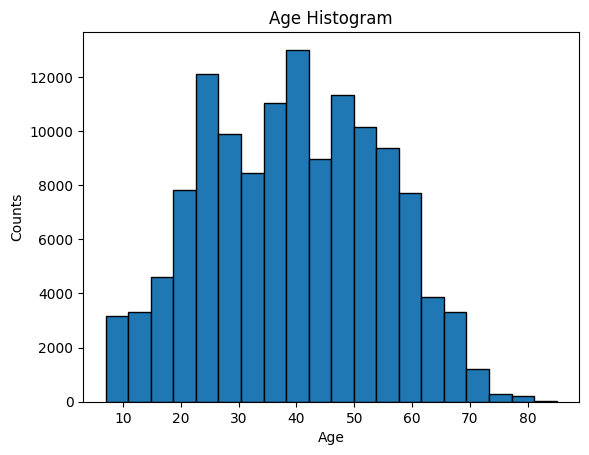

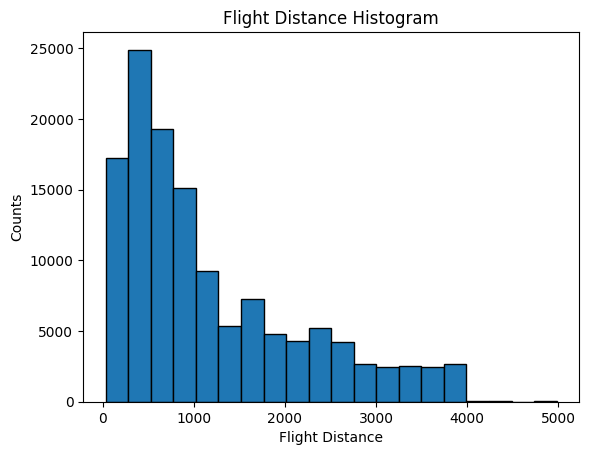

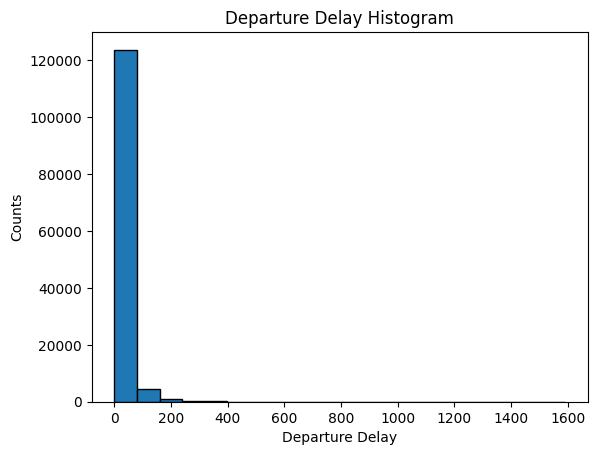

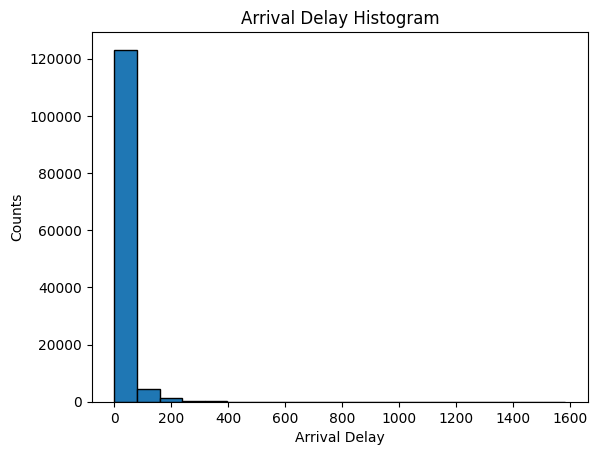

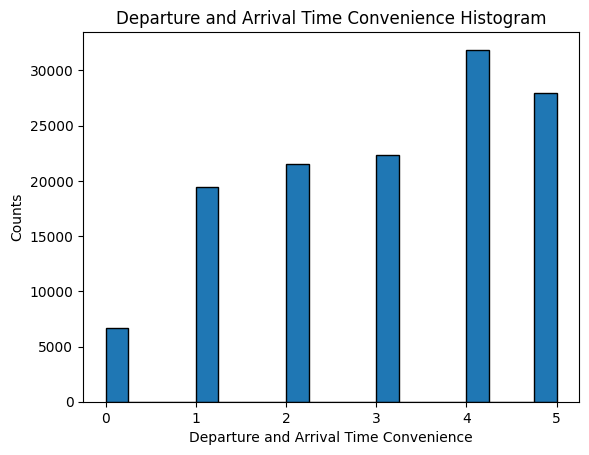

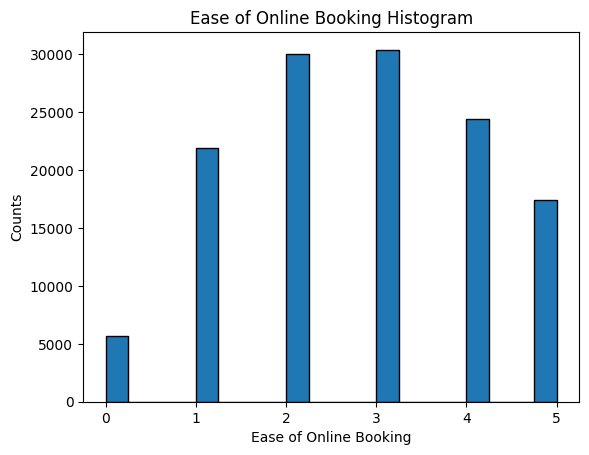

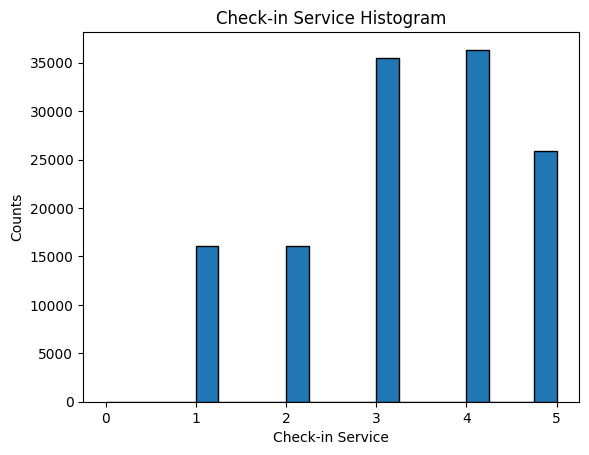

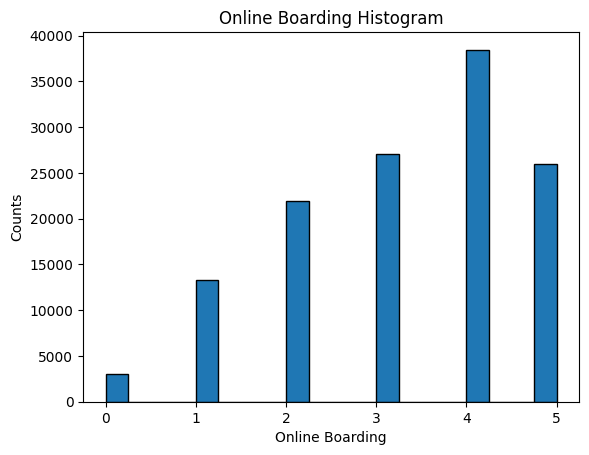

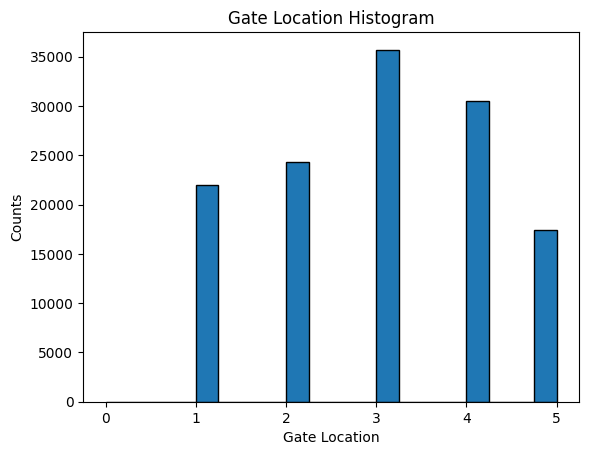

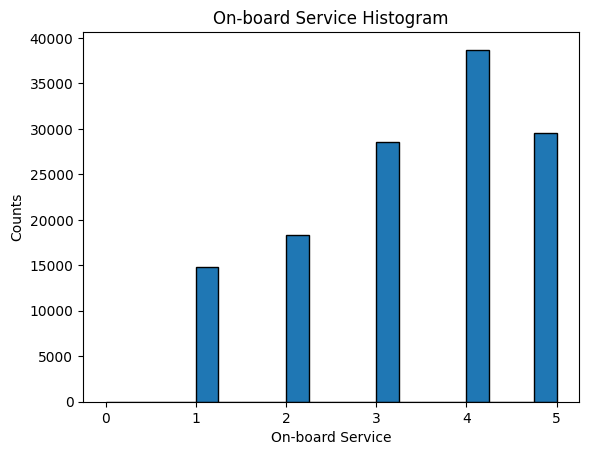

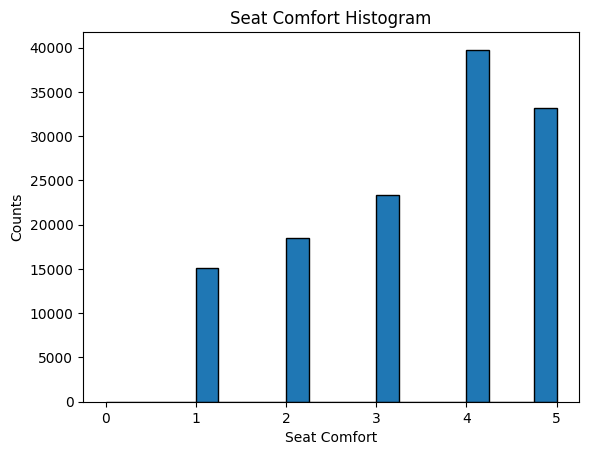

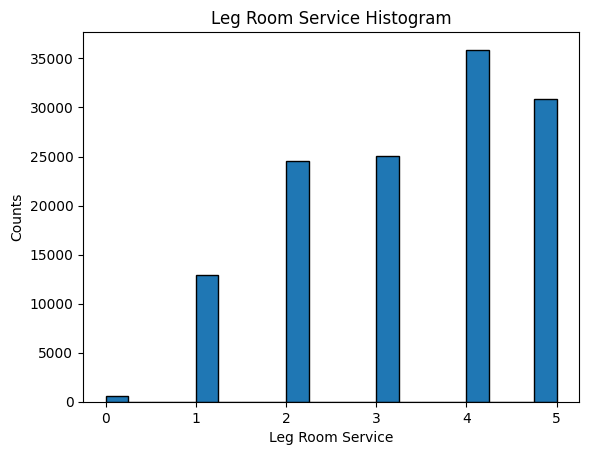

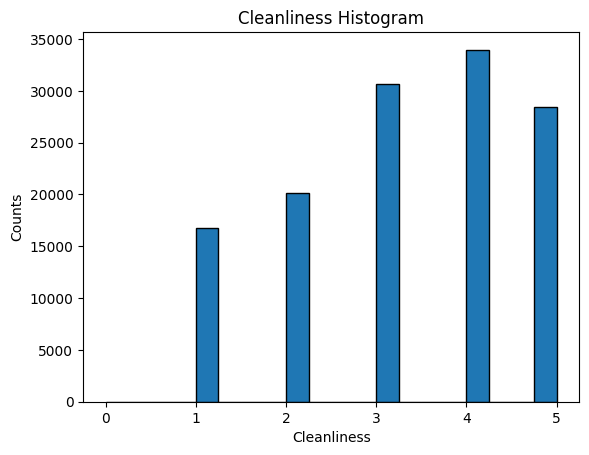

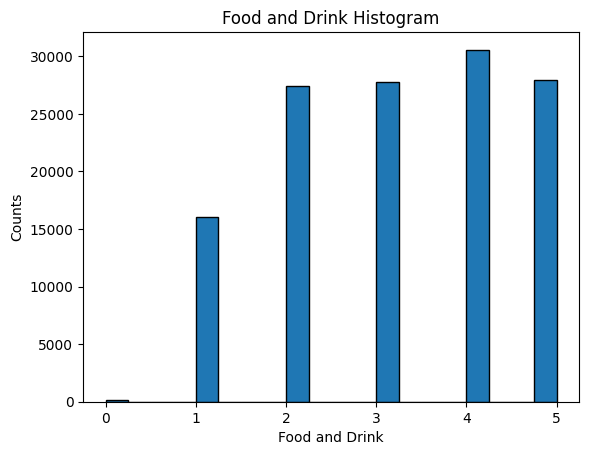

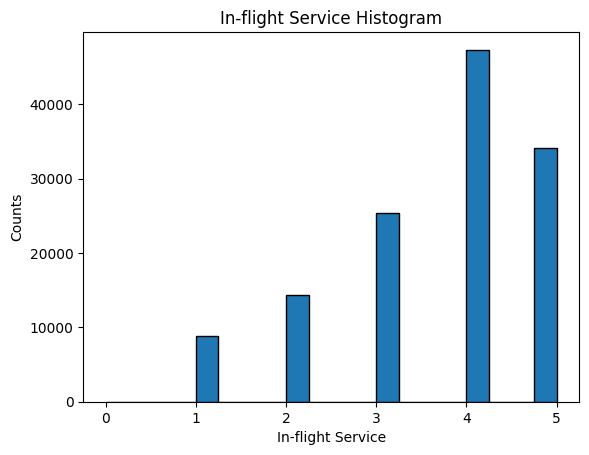

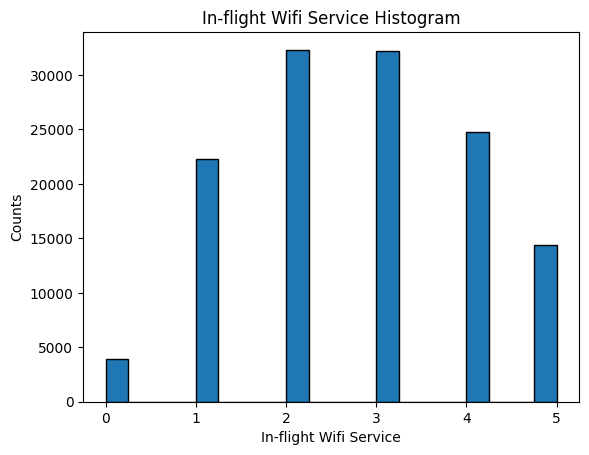

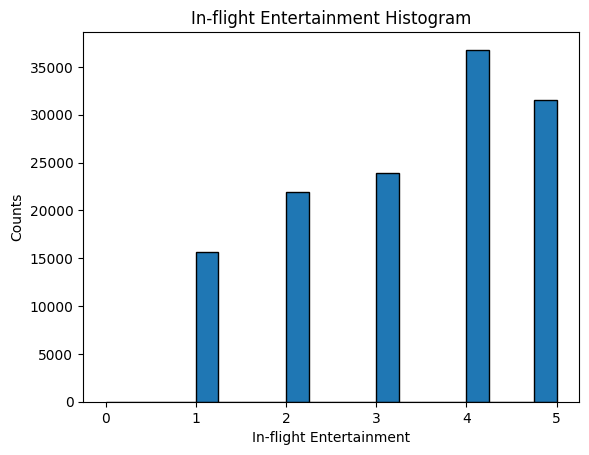

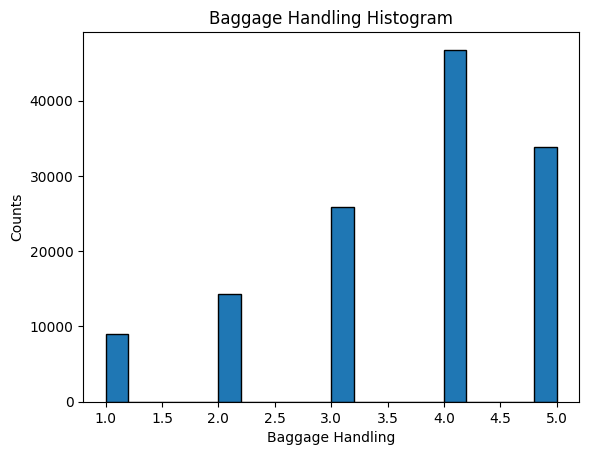

In [12]:
numeric_cols = ['Age', 'Flight Distance', 'Departure Delay', 'Arrival Delay',
                'Departure and Arrival Time Convenience', 'Ease of Online Booking', 'Check-in Service',
                'Online Boarding', 'Gate Location', 'On-board Service', 'Seat Comfort', 'Leg Room Service',
                'Cleanliness', 'Food and Drink', 'In-flight Service', 'In-flight Wifi Service',
                'In-flight Entertainment', 'Baggage Handling']

for col in numeric_cols:
    df[col].hist(bins=20, edgecolor='black')
    plt.title(f'{col} Histogram')
    plt.xlabel(col)
    plt.ylabel('Counts')
    plt.grid(False)
    plt.show()

## Ραβδογράμματα Κατηγορικών Μεταβλητών

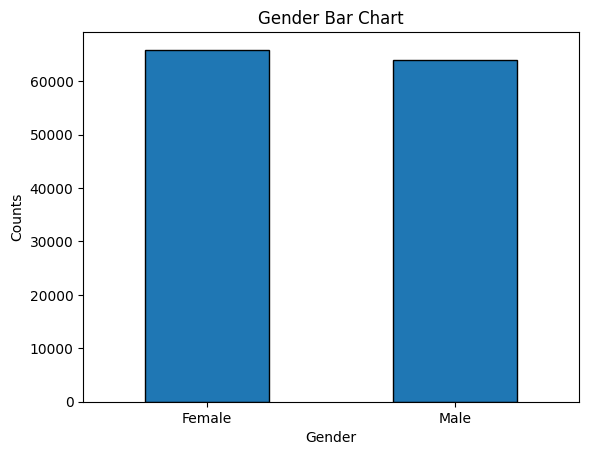

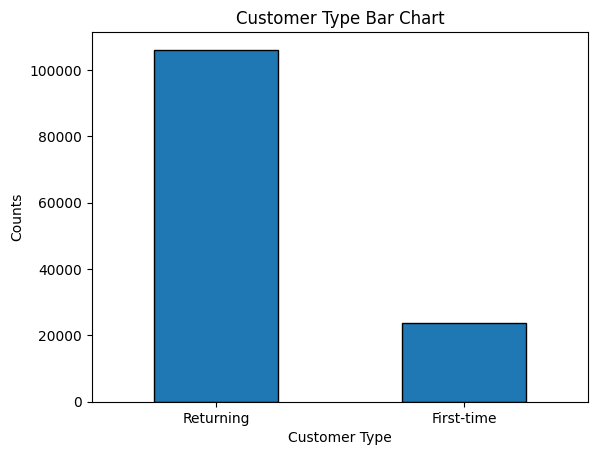

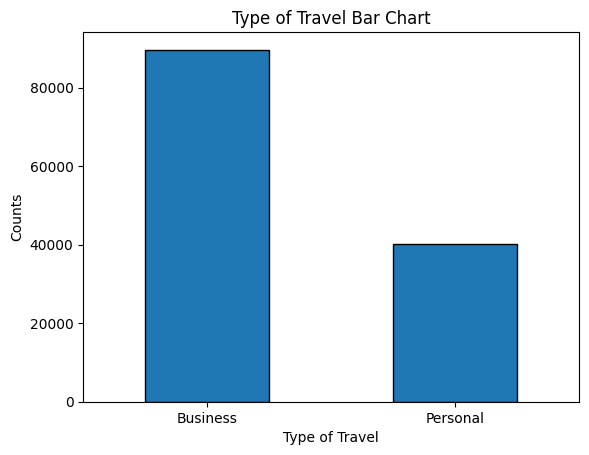

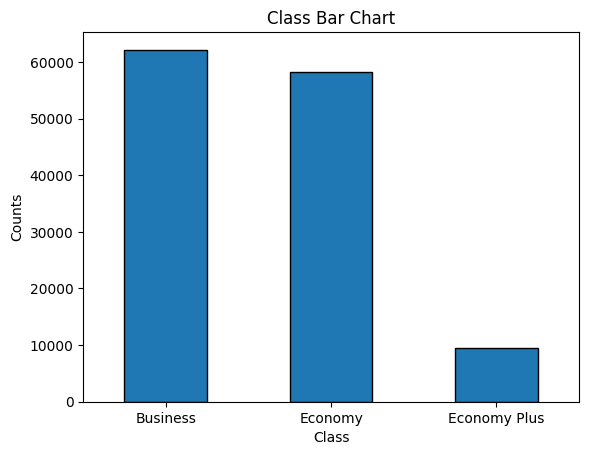

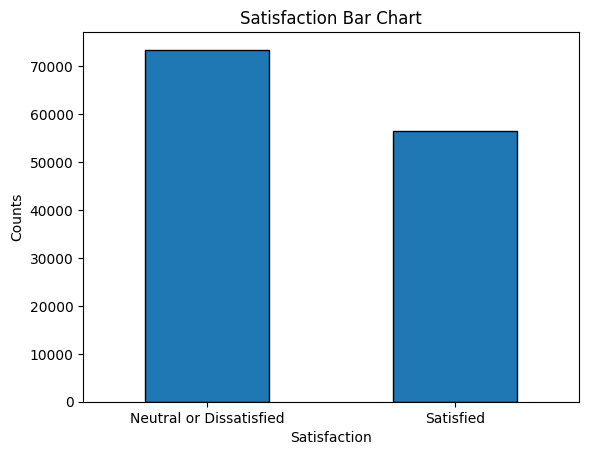

In [13]:
categorical_cols = ['Gender', 'Customer Type', 'Type of Travel', 'Class', 'Satisfaction']

for col in categorical_cols:
    df[col].value_counts().plot(kind='bar', edgecolor='black')
    plt.title(f'{col} Bar Chart')
    plt.xlabel(col)
    plt.ylabel('Counts')
    plt.xticks(rotation=0)
    plt.grid(False)
    plt.show()

## Ισορροπία Κλάσεων (Satisfaction)

In [14]:
df['Satisfaction'].value_counts()
df['Satisfaction'].value_counts(normalize=True).round(2) * 100

,proportion
Satisfaction,
Neutral or Dissatisfied,57.0
Satisfied,43.0


Η κλάση Neutral or Dissatisfied έχει περισσότερα παραδείγματα, άρα υπερισχύει ελαφρώς. Η διαφορά όμως δεν είναι μεγάλη (περίπου 57–43), οπότε οι κλάσεις είναι σχετικά μη ισορροπημένες.

# **2. Κωδικοποίηση Κατηγορικών Μεταβλητών**



*   **Gender, Customer Type, Type of Travel** : έχουν μόνο 2 τιμές, οπότε αρκεί μία δυαδική στήλη 0/1.
*   **Satisfaction** (κλάση) : 0 = Neutral or Dissatisfied, 1 = Satisfied.
*   **Class** : μπορεί να κωδικοποιηθεί **με δύο τρόπους**:
    *   **Ordinal**: Economy = 0, Economy Plus = 1, Business = 2, γιατί οι θέσεις έχουν φυσική σειρά (επίπεδο υπηρεσίας).
    *   **One-Hot**: μία στήλη για κάθε θέση, όπου όλες οι θέσεις απέχουν το ίδιο μεταξύ τους.

Για το μοντέλο χρησιμοποιούμε την ordinal κωδικοποίηση της Class, γιατί η απόσταση Economy–Business (2) είναι λογικό να είναι μεγαλύτερη από την Economy–Economy Plus (1).

In [15]:
df['Gender'] = df['Gender'].map({'Female': 0, 'Male': 1})
df['Customer Type'] = df['Customer Type'].map({'First-time': 0, 'Returning': 1})
df['Type of Travel'] = df['Type of Travel'].map({'Business': 0, 'Personal': 1})
df['Satisfaction'] = df['Satisfaction'].map({'Neutral or Dissatisfied': 0, 'Satisfied': 1})
df

,Gender,Age,Customer Type,Type of Travel,Class,Flight Distance,Departure Delay,Arrival Delay,Departure and Arrival Time Convenience,Ease of Online Booking,...,On-board Service,Seat Comfort,Leg Room Service,Cleanliness,Food and Drink,In-flight Service,In-flight Wifi Service,In-flight Entertainment,Baggage Handling,Satisfaction
0,1,48,0,0,Business,821,2,5.0,3,3,...,3,5,2,5,5,5,3,5,5,0
1,0,35,1,0,Business,821,26,39.0,2,2,...,5,4,5,5,3,5,2,5,5,1
2,1,41,1,0,Business,853,0,0.0,4,4,...,3,5,3,5,5,3,4,3,3,1
3,1,50,1,0,Business,1905,0,0.0,2,2,...,5,5,5,4,4,5,2,5,5,1
4,0,49,1,0,Business,3470,0,1.0,3,3,...,3,4,4,5,4,3,3,3,3,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
129875,1,28,1,1,Economy Plus,447,2,3.0,4,4,...,5,1,4,4,4,5,4,4,4,0
129876,1,41,1,1,Economy Plus,308,0,0.0,5,3,...,5,2,5,2,2,4,3,2,5,0
129877,1,42,1,1,Economy Plus,337,6,14.0,5,2,...,3,3,4,3,3,4,2,3,5,0
129878,1,50,1,1,Economy Plus,337,31,22.0,4,4,...,4,4,5,3,3,4,5,3,5,1


In [16]:
df['Class'] = df['Class'].map({'Economy': 0, 'Economy Plus': 1, 'Business': 2})
df.head()

,Gender,Age,Customer Type,Type of Travel,Class,Flight Distance,Departure Delay,Arrival Delay,Departure and Arrival Time Convenience,Ease of Online Booking,...,On-board Service,Seat Comfort,Leg Room Service,Cleanliness,Food and Drink,In-flight Service,In-flight Wifi Service,In-flight Entertainment,Baggage Handling,Satisfaction
0,1,48,0,0,2,821,2,5.0,3,3,...,3,5,2,5,5,5,3,5,5,0
1,0,35,1,0,2,821,26,39.0,2,2,...,5,4,5,5,3,5,2,5,5,1
2,1,41,1,0,2,853,0,0.0,4,4,...,3,5,3,5,5,3,4,3,3,1
3,1,50,1,0,2,1905,0,0.0,2,2,...,5,5,5,4,4,5,2,5,5,1
4,0,49,1,0,2,3470,0,1.0,3,3,...,3,4,4,5,4,3,3,3,3,1


# **3. Numpy Arrays and Train - Test Datasets**

In [17]:
input_df = df.drop(columns=['Satisfaction'])
targets_df = df['Satisfaction']

x = input_df.to_numpy(dtype=np.float64)
y = targets_df.to_numpy()
x.shape, y.shape

((129880, 22), (129880,))

## Split Dataset to Train-Test

Train Samples: 691
Test Samples: 77
Seed: 0

Seed enables reproducibility

In [18]:
seed = 0
test_size = 0.3

x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=test_size, random_state=seed)
x_train.shape, y_train.shape, x_test.shape, y_test.shape

((90916, 22), (90916,), (38964, 22), (38964,))

In [20]:
print(f'Number of training samples: {x_train.shape[0]}')
print(f'Number of test samples: {x_test.shape[0]}')

Number of training samples: 90916
Number of test samples: 38964


# **4. Κανονικοποίηση Αριθμητικών Μεταβλητών**


Ο KNN βρίσκει τους γείτονες με βάση την απόσταση. Λόγω των μεγάλων τιμών του Flight Distance και Delay αυτές οι τιμές θα καθόριζαν μόνες τους την απόσταση.

Χρησιμοποιούμε Z-Score (StandardScaler) και όχι Min-Max, γιατί οι καθυστερήσεις έχουν ακραίες τιμές: με Min-Max η μεγαλύτερη καθυστέρηση θα γινόταν 1 και σχεδόν όλες οι υπόλοιπες τιμές θα ήταν κοντά στο 0.

Οι δυαδικές (Gender, Customer Type, Type of Travel) μένουν 0/1. Ο scaler κάνει fit μόνο στο train set και μετά transform σε train και test.

In [21]:
numeric_idx = [input_df.columns.get_loc(col) for col in numeric_cols]

scaler = StandardScaler()
scaler.fit(x_train[:, numeric_idx])

x_train[:, numeric_idx] = scaler.transform(x_train[:, numeric_idx])
x_test[:, numeric_idx] = scaler.transform(x_test[:, numeric_idx])

pd.DataFrame(x_train, columns=input_df.columns).describe().loc[['mean', 'std']].round(2)

,Gender,Age,Customer Type,Type of Travel,Class,Flight Distance,Departure Delay,Arrival Delay,Departure and Arrival Time Convenience,Ease of Online Booking,...,Gate Location,On-board Service,Seat Comfort,Leg Room Service,Cleanliness,Food and Drink,In-flight Service,In-flight Wifi Service,In-flight Entertainment,Baggage Handling
mean,0.49,-0.0,0.82,0.31,1.03,0.0,0.0,-0.0,-0.0,0.0,...,-0.0,0.0,0.0,0.0,0.0,-0.0,-0.0,0.0,0.0,0.0
std,0.50,1.0,0.39,0.46,0.96,1.0,1.0,1.0,1.0,1.0,...,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0


# **5. KNN Classifier**


Ο KNN δεν εκπαιδεύεται από πριν. Κάθε φορά που κάνει μια πρόβλεψη, συγκρίνει το νέο παράδειγμα με όλα τα παραδείγματα του train, για να βρει ποια είναι τα πιο κοντινά. Αυτό είναι πολύ αργό και επομένως, μετράμε την ακρίβεια σε 5.000 παραδείγματα του train και του test αντί για όλα για λόγους χρόνου και μειώνουμε τις προβλέψεις για λόγους μνήμης (500 κάθε φορά).

In [22]:
num_eval_samples = 5000

def predict_in_batches(model, x, batch_size=500):
    y_pred = [model.predict(x[i: i + batch_size]) for i in range(0, x.shape[0], batch_size)]
    return np.concatenate(y_pred)

## Train - Test Accuracy για τους 12 συνδυασμούς

In [25]:
import numpy as np

# Impute NaN values with 0 (or median) to fix the ValueError
x_train = np.nan_to_num(x_train, nan=0.0)
x_test = np.nan_to_num(x_test, nan=0.0)

N = x_train.shape[0]
k_values = [3, 5, 15, 51, 151, N]
weights_values = ['uniform', 'distance']

results = []
for k in k_values:
    for weights in weights_values:
        model = KNeighborsClassifier(n_neighbors=k, weights=weights, metric='euclidean')
        model.fit(x_train, y_train)

        y_pred = predict_in_batches(model, x_train[:num_eval_samples])
        train_accuracy = accuracy_score(y_train[:num_eval_samples], y_pred)
        y_pred = predict_in_batches(model, x_test[:num_eval_samples])
        test_accuracy = accuracy_score(y_test[:num_eval_samples], y_pred)

        results.append({'k': k, 'weights': weights,
                        'Train Accuracy (%)': round(train_accuracy * 100, 2),
                        'Test Accuracy (%)': round(test_accuracy * 100, 2)})
        print(f'k = {k}, weights = {weights}: train = {train_accuracy*100:.2f}%, test = {test_accuracy*100:.2f}%')

results_df = pd.DataFrame(results)
results_df

k = 3, weights = uniform: train = 95.54%, test = 93.08%
k = 3, weights = distance: train = 100.00%, test = 93.10%
k = 5, weights = uniform: train = 94.58%, test = 93.38%
k = 5, weights = distance: train = 100.00%, test = 93.40%
k = 15, weights = uniform: train = 93.36%, test = 93.30%
k = 15, weights = distance: train = 100.00%, test = 93.34%
k = 51, weights = uniform: train = 91.72%, test = 92.50%
k = 51, weights = distance: train = 100.00%, test = 92.64%
k = 151, weights = uniform: train = 90.76%, test = 91.12%
k = 151, weights = distance: train = 100.00%, test = 91.28%
k = 90916, weights = uniform: train = 56.26%, test = 55.96%
k = 90916, weights = distance: train = 100.00%, test = 64.76%


,k,weights,Train Accuracy (%),Test Accuracy (%)
0,3,uniform,95.54,93.08
1,3,distance,100.00,93.10
2,5,uniform,94.58,93.38
3,5,distance,100.00,93.40
4,15,uniform,93.36,93.30
5,15,distance,100.00,93.34
6,51,uniform,91.72,92.50
7,51,distance,100.00,92.64
8,151,uniform,90.76,91.12
9,151,distance,100.00,91.28


In [26]:
best = results_df.loc[results_df['Test Accuracy (%)'].idxmax()]
print(f"Καλύτερος συνδυασμός: k = {best['k']}, weights = {best['weights']}, Test Accuracy = {best['Test Accuracy (%)']}%")

Καλύτερος συνδυασμός: k = 5, weights = distance, Test Accuracy = 93.4%


## Παρατηρήσεις

- Μικρό k (3, 5, 15): η καλύτερη ακρίβεια στο test (~93.1–93.4%). Με k = 3 η ακρίβεια στο train (95.5%) είναι αισθητά μεγαλύτερη από το test (93.1%), δηλαδή υπάρχει τάση για overfitting. Όσο μεγαλώνει το k, το κενό train–test μικραίνει.
- distance βάρη: η ακρίβεια στο train είναι 100%, γιατί κάθε παράδειγμα του train βρίσκει τον εαυτό του με απόσταση 0 και παίρνει όλο το βάρος.
- Μεγάλο k (51, 151): η ακρίβεια πέφτει σιγά σιγά (92.6% και 91.3%), γιατί ψηφίζουν και πιο μακρινά, λιγότερο σχετικά παραδείγματα.
- k = N, uniform: ψηφίζουν όλα τα παραδείγματα ισότιμα, οπότε ο αλγόριθμος προβλέπει πάντα την πλειοψηφούσα κλάση και η ακρίβεια είναι ~56%, όσο το ποσοστό της κλάσης Neutral or Dissatisfied.
- k = N, distance: τα βάρη 1/d βοηθούν λίγο (~65%), γιατί τα κοντινά σημεία μετράνε περισσότερο, αλλά οι μακρινοί γείτονες προσθέτουν πολύ θόρυβο.

Καλύτερος συνδυασμός: k = 5 με βάρη distance (93.42% στο test), με πολύ μικρή διαφορά από τα k = 5 uniform και k = 15. Η ακρίβεια είναι πολύ πάνω από το 56.55%, οπότε η εταιρεία μπορεί να εντοπίζει με καλή ακρίβεια τους δυσαρεστημένους πελάτες.
